# sam_1_v2 — `sam_1.ipynb` 수정본

원본 `C:\t_project_1_1\sam_1.ipynb`은 원본 CSV 전체(260,601행)를 읽었습니다. 여기에는 팀 `final_holdout` 52,121행의 정답도 포함됩니다.
팀 규칙상 홀드아웃의 입력-정답 관계는 탐색하지 않으므로, 이 복사본은 **팀 development 208,480행만** 읽습니다.
원본 셀 0은 다른 데이터셋(신용카드 사기, `Class`·`V1~V28` 열)용 코드라 이 데이터에서 실행되지 않아 삭제했고, 빈 셀 2도 삭제했습니다.

분석 코드는 원본과 같고, 바뀐 것은 데이터 경로와 저장 경로뿐입니다. 그래서 건수와 비율 숫자는 원본과 다르게 나옵니다.

In [ ]:
# [v2] 팀 development 데이터만 사용 (final_holdout 제외)
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "preprocess.py").exists())
DEV_CSV = REPO / "data" / "development.csv"   # 원본 CSV에서 팀 홀드아웃 52,121행을 뺀 208,480행
OUT_DIR = REPO / "outputs" / "t_project_v2" / "sam_1"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("데이터:", DEV_CSV)
print("저장 폴더:", OUT_DIR)

데이터: C:\Users\jhj31\project_1\earthquake\data\development.csv
저장 폴더: C:\Users\jhj31\project_1\earthquake\outputs\t_project_v2\sam_1


1. 데이터 구조
행 x 열 : (208480, 40)

[info]
<class 'pandas.DataFrame'>
RangeIndex: 208480 entries, 0 to 208479
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   building_id                             208480 non-null  int64
 1   geo_level_1_id                          208480 non-null  int64
 2   geo_level_2_id                          208480 non-null  int64
 3   geo_level_3_id                          208480 non-null  int64
 4   count_floors_pre_eq                     208480 non-null  int64
 5   age                                     208480 non-null  int64
 6   area_percentage                         208480 non-null  int64
 7   height_percentage                       208480 non-null  int64
 8   land_surface_condition                  208480 non-null  str  
 9   foundation_type                         208480 non-null  str  
 10  roof_type                               


결측 셀 수 : 0
building_id 고유값 : 208480 / 208480

2. 피해 등급 분포 (클래스 불균형)
             건수  비율(%)
1등급(경미)   20099   9.64
2등급(중간)  118607  56.89
3등급(심각)   69774  33.47

최다 등급으로만 예측했을 때의 정확도 : 0.5689
  -> 정확도만 보면 이 값을 넘어야 의미가 있음


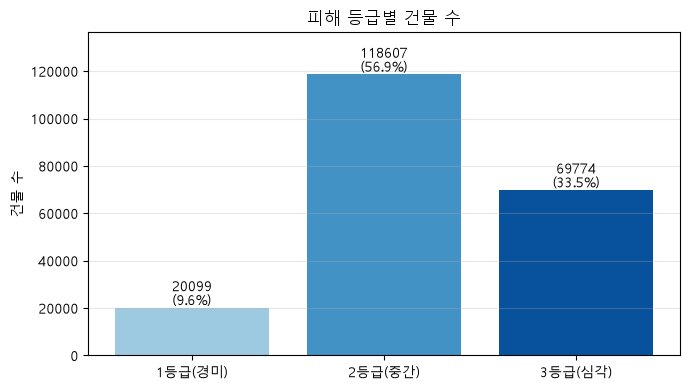


3. 상부구조 재료별 피해 등급 분포
                 재료   건물 수  사용 비율(%)  1등급(%)  2등급(%)  3등급(%)
         stone_flag   7129      3.42     2.0    50.5    47.5
   mud_mortar_stone 158774     76.16     4.4    57.4    38.2
          adobe_mud  18529      8.89     2.6    60.0    37.4
   mud_mortar_brick  14276      6.85     3.5    65.8    30.8
             timber  53163     25.50    11.5    60.3    28.1
              other   3121      1.50    17.2    57.5    25.3
             bamboo  17783      8.53    12.8    63.3    23.9
cement_mortar_stone   3804      1.82    17.5    68.2    14.3
  rc_non_engineered   8922      4.28    34.7    52.5    12.8
cement_mortar_brick  15658      7.51    36.2    58.2     5.5
      rc_engineered   3300      1.58    64.4    33.8     1.9

[주의] 재료는 다중 플래그이므로 비율 합계가 100%를 넘습니다.


건물당 사용 재료 개수 분포 :
1    140745
2     46318
3     16171
4      3963
5      1015
6       239
7        28
8         1


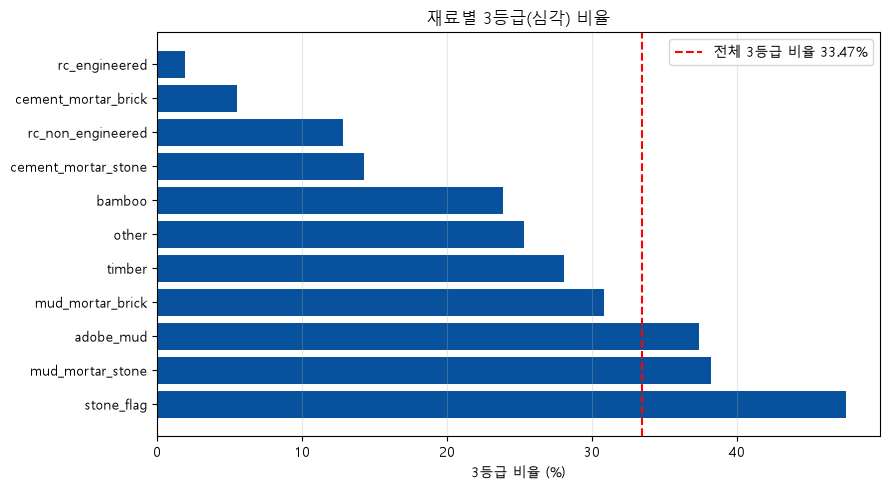


4. 지역(geo_level_1)별 피해 등급 분포
                1등급(%)  2등급(%)  3등급(%)   건물 수
geo_level_1_id                               
17                 1.3    18.0    80.7  17370
18                 2.3    24.3    73.4   2530
21                 2.2    39.7    58.1  11864
8                  3.4    44.6    52.1  15331
27                 3.8    47.8    48.4  10015
...
                1등급(%)  2등급(%)  3등급(%)   건물 수
geo_level_1_id                               
30                 8.9    79.7    11.4   2103
29                 2.1    87.5    10.3    329
24                21.6    69.2     9.2   1031
5                 15.9    75.5     8.5   2190
26                35.6    55.9     8.5  18038

3등급 비율 범위 : 8.5% ~ 80.7%
geo_level_1_id   고유값     31개
geo_level_2_id   고유값   1408개
geo_level_3_id   고유값  11353개


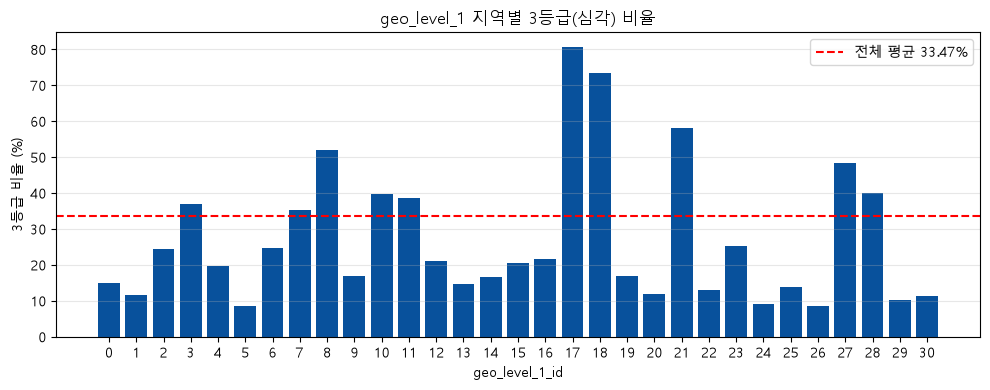


5. 재료를 고정했을 때의 지역별 차이
진흙모르타르-석재 단독 사용 건물 : 109735 건

500건 이상 지역 25개의 3등급 비율 : 9.5% ~ 84.0%
                 건물 수  3등급(%)
geo_level_1_id               
17              12739    84.0
18               1108    81.8
27               1930    61.8
                건물 수  3등급(%)
geo_level_1_id              
1               1506    12.1
30              1525    12.1
5               1445     9.5

-> 같은 재료여도 지역에 따라 차이가 큼.
   재료만으로 원인을 단정할 수 없고, 지역이 담은 정보(진동 강도 등)를 고려해야 함

6. 구조 범주형 변수별 피해 등급 분포

[foundation_type]
                 1등급(%)  2등급(%)  3등급(%)    건물 수
foundation_type                                
h                  25.5    38.1    36.4    1191
i                  56.6    41.3     2.2    8465
r                   4.9    57.3    37.9  175259
u                  25.9    60.1    14.0   11436
w                  28.8    61.2    10.0   12129

[roof_type]
           1등급(%)  2등급(%)  3등급(%)    건물 수
roof_type                                
n             7.4    58.2    34.4  146185
q             6.5  


[ground_floor_type]
                   1등급(%)  2등급(%)  3등급(%)    건물 수
ground_floor_type                                
f                     5.9    57.2    36.8  167644
m                    18.2    66.3    15.4     395
v                    41.9    52.7     5.3   19629
x                     8.3    58.3    33.5   20029
z                    20.4    52.6    26.9     783

[other_floor_type]
                  1등급(%)  2등급(%)  3등급(%)    건물 수
other_floor_type                                
j                   22.1    51.0    26.8   31907
q                    4.5    59.5    36.0  132216
s                   45.2    49.1     5.7    9622
x                    8.0    54.5    37.6   34735

7. 수치형 변수 분포
       count_floors_pre_eq        age  area_percentage  height_percentage  count_families
count            208480.00  208480.00        208480.00          208480.00       208480.00
mean                  2.13      26.60             8.02               5.43            0.98
std                   0.73     

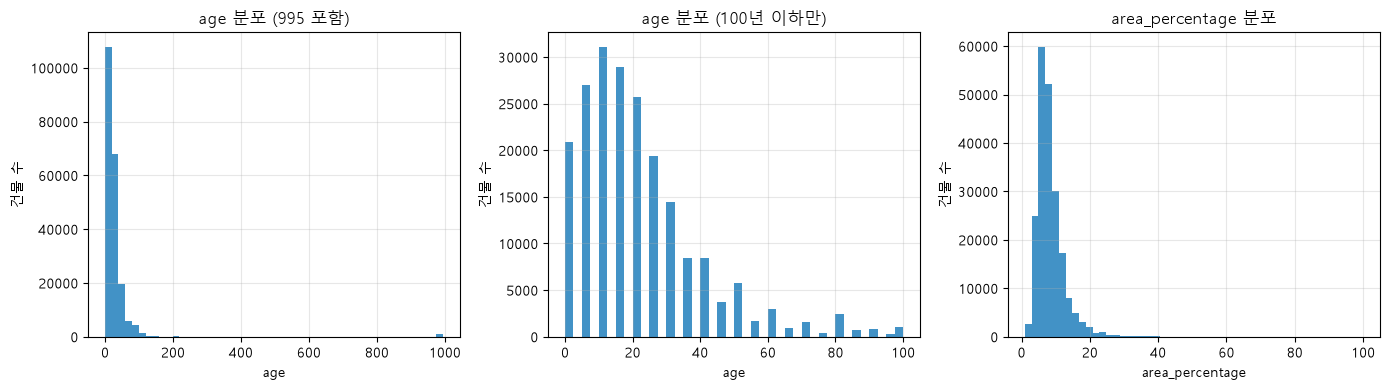


8. 3등급(심각) 건물의 특성 - 과소 예측 분석의 사전 작업
[수치형 평균 비교]
                     3등급 평균  1등급 평균  전체 평균
count_floors_pre_eq    2.21    1.85   2.13
age                   27.91   17.50  26.60
area_percentage        7.50    9.72   8.02
height_percentage      5.52    5.16   5.43
count_families         1.01    0.92   0.98

[재료 사용률 비교 (%)]
                     3등급(%)  1등급(%)  전체(%)  차이(3-1)
mud_mortar_stone      86.84   34.81  76.16    52.03
adobe_mud              9.93    2.39   8.89     7.54
stone_flag             4.85    0.72   3.42     4.13
mud_mortar_brick       6.30    2.46   6.85     3.84
other                  1.13    2.68   1.50    -1.55
cement_mortar_stone    0.78    3.31   1.82    -2.53
bamboo                 6.09   11.32   8.53    -5.23
timber                21.42   30.55  25.50    -9.13
rc_engineered          0.09   10.57   1.58   -10.48
rc_non_engineered      1.64   15.40   4.28   -13.76
cement_mortar_brick    1.24   28.24   7.51   -27.00

그림은 C:\Users\jhj31\project_1\earthquake\outputs\t_p

In [2]:
# -*- coding: utf-8 -*-
"""
네팔 지진 건물 피해 등급 예측 - 01. 탐색적 데이터 분석(EDA)

[분석 목적과의 연결]
 - 피해 등급 분류를 위한 데이터 구조와 클래스 불균형 확인
 - 등급과 '관련된' 주요 특성 파악 (인과관계 주장 아님)
 - 심한 피해(3등급) 건물이 어떤 특성을 갖는지 사전 확인

실행: python 01_eda.py
"""

import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 0. 기본 설정
# ---------------------------------------------------------------
CSV_PATH = DEV_CSV  # [v2] 팀 development
FIG_DIR = str(OUT_DIR / "figures")  # [v2]

import os
os.makedirs(FIG_DIR, exist_ok=True)

# 한글 폰트 설정 (Windows: 맑은 고딕 / Mac: AppleGothic)
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"]:
    try:
        plt.rcParams["font.family"] = font
        break
    except Exception:
        continue
plt.rcParams["axes.unicode_minus"] = False

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

TARGET = "damage_grade"
GRADE_NAME = {1: "1등급(경미)", 2: "2등급(중간)", 3: "3등급(심각)"}

NUM_COLS = ["count_floors_pre_eq", "age", "area_percentage",
            "height_percentage", "count_families"]
CAT_COLS = ["land_surface_condition", "foundation_type", "roof_type",
            "ground_floor_type", "other_floor_type", "position",
            "plan_configuration", "legal_ownership_status"]
SUP_COLS = [  # 상부구조 재료 11개
    "has_superstructure_adobe_mud", "has_superstructure_mud_mortar_stone",
    "has_superstructure_stone_flag", "has_superstructure_cement_mortar_stone",
    "has_superstructure_mud_mortar_brick", "has_superstructure_cement_mortar_brick",
    "has_superstructure_timber", "has_superstructure_bamboo",
    "has_superstructure_rc_non_engineered", "has_superstructure_rc_engineered",
    "has_superstructure_other"]

df = pd.read_csv(CSV_PATH)


# ---------------------------------------------------------------
# 1. 데이터 구조 확인
# ---------------------------------------------------------------
def step1_structure():
    print("=" * 70)
    print("1. 데이터 구조")
    print("=" * 70)
    print("행 x 열 :", df.shape)
    print("\n[info]")
    df.info()
    print("\n[describe - 수치형]")
    print(df[NUM_COLS].describe().round(2).to_string())
    print("\n결측 셀 수 :", df.isnull().sum().sum())
    print("building_id 고유값 :", df["building_id"].nunique(), "/", len(df))


# ---------------------------------------------------------------
# 2. 타깃 분포 - 클래스 불균형 확인
# ---------------------------------------------------------------
def step2_target():
    print("\n" + "=" * 70)
    print("2. 피해 등급 분포 (클래스 불균형)")
    print("=" * 70)

    cnt = df[TARGET].value_counts().sort_index()
    pct = (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2)
    tbl = pd.DataFrame({"건수": cnt, "비율(%)": pct})
    tbl.index = [GRADE_NAME[i] for i in tbl.index]
    print(tbl.to_string())

    print("\n최다 등급으로만 예측했을 때의 정확도 : %.4f" % (cnt.max() / len(df)))
    print("  -> 정확도만 보면 이 값을 넘어야 의미가 있음")

    plt.figure(figsize=(7, 4))
    plt.bar([GRADE_NAME[i] for i in cnt.index], cnt.values,
            color=["#9ecae1", "#4292c6", "#08519c"])
    for i, v in enumerate(cnt.values):
        plt.text(i, v, "%d\n(%.1f%%)" % (v, pct.values[i]),
                 ha="center", va="bottom")
    plt.title("피해 등급별 건물 수")
    plt.ylabel("건물 수")
    plt.grid(True, axis="y", alpha=0.3)
    plt.ylim(0, cnt.max() * 1.15)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/fig1_target.png", dpi=120)
    plt.show()


# ---------------------------------------------------------------
# 3. 상부구조 재료와 피해 등급의 관련성
#    주의: 한 건물이 여러 재료를 동시에 쓸 수 있는 다중 플래그
# ---------------------------------------------------------------
def step3_material():
    print("\n" + "=" * 70)
    print("3. 상부구조 재료별 피해 등급 분포")
    print("=" * 70)

    rows = []
    for col in SUP_COLS:
        used = df[df[col] == 1]
        if len(used) == 0:
            continue
        p = used[TARGET].value_counts(normalize=True).sort_index() * 100
        rows.append({
            "재료": col.replace("has_superstructure_", ""),
            "건물 수": len(used),
            "사용 비율(%)": round(len(used) / len(df) * 100, 2),
            "1등급(%)": round(p.get(1, 0), 1),
            "2등급(%)": round(p.get(2, 0), 1),
            "3등급(%)": round(p.get(3, 0), 1),
        })
    mat = pd.DataFrame(rows).sort_values("3등급(%)", ascending=False)
    print(mat.to_string(index=False))

    print("\n[주의] 재료는 다중 플래그이므로 비율 합계가 100%를 넘습니다.")
    n_mat = df[SUP_COLS].sum(axis=1)
    print("건물당 사용 재료 개수 분포 :")
    print(n_mat.value_counts().sort_index().to_string())

    plt.figure(figsize=(9, 5))
    plt.barh(mat["재료"], mat["3등급(%)"], color="#08519c")
    plt.axvline(33.47, color="red", linestyle="--",
                label="전체 3등급 비율 33.47%")
    plt.title("재료별 3등급(심각) 비율")
    plt.xlabel("3등급 비율 (%)")
    plt.legend()
    plt.grid(True, axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/fig2_material.png", dpi=120)
    plt.show()


# ---------------------------------------------------------------
# 4. 지역과 피해 등급의 관련성
# ---------------------------------------------------------------
def step4_geo():
    print("\n" + "=" * 70)
    print("4. 지역(geo_level_1)별 피해 등급 분포")
    print("=" * 70)

    ct = pd.crosstab(df["geo_level_1_id"], df[TARGET], normalize="index") * 100
    ct.columns = ["1등급(%)", "2등급(%)", "3등급(%)"]
    ct["건물 수"] = df["geo_level_1_id"].value_counts()
    ct = ct.sort_values("3등급(%)", ascending=False).round(1)
    print(ct.head(5).to_string())
    print("...")
    print(ct.tail(5).to_string())
    print("\n3등급 비율 범위 : %.1f%% ~ %.1f%%"
          % (ct["3등급(%)"].min(), ct["3등급(%)"].max()))

    for col in ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]:
        print("%-16s 고유값 %6d개" % (col, df[col].nunique()))

    plt.figure(figsize=(10, 4))
    s = ct.sort_index()
    plt.bar(s.index.astype(str), s["3등급(%)"], color="#08519c")
    plt.axhline(33.47, color="red", linestyle="--", label="전체 평균 33.47%")
    plt.title("geo_level_1 지역별 3등급(심각) 비율")
    plt.xlabel("geo_level_1_id")
    plt.ylabel("3등급 비율 (%)")
    plt.legend()
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/fig3_geo.png", dpi=120)
    plt.show()


# ---------------------------------------------------------------
# 5. 재료를 고정해도 지역 차이가 남는가
#    -> '재료 때문'이라고 단정할 수 없음을 보이는 근거
# ---------------------------------------------------------------
def step5_geo_material():
    print("\n" + "=" * 70)
    print("5. 재료를 고정했을 때의 지역별 차이")
    print("=" * 70)

    only_mms = df[(df["has_superstructure_mud_mortar_stone"] == 1)
                  & (df[SUP_COLS].sum(axis=1) == 1)]
    print("진흙모르타르-석재 단독 사용 건물 :", len(only_mms), "건")

    g3 = (only_mms[only_mms[TARGET] == 3].groupby("geo_level_1_id").size()
          / only_mms.groupby("geo_level_1_id").size() * 100)
    size = only_mms.groupby("geo_level_1_id").size()
    res = pd.DataFrame({"건물 수": size, "3등급(%)": g3.round(1)})
    res = res[res["건물 수"] >= 500].sort_values("3등급(%)", ascending=False)
    print("\n500건 이상 지역 %d개의 3등급 비율 : %.1f%% ~ %.1f%%"
          % (len(res), res["3등급(%)"].min(), res["3등급(%)"].max()))
    print(res.head(3).to_string())
    print(res.tail(3).to_string())
    print("\n-> 같은 재료여도 지역에 따라 차이가 큼.")
    print("   재료만으로 원인을 단정할 수 없고, 지역이 담은 정보(진동 강도 등)를 고려해야 함")


# ---------------------------------------------------------------
# 6. 구조 관련 범주형 변수와 피해 등급
# ---------------------------------------------------------------
def step6_category():
    print("\n" + "=" * 70)
    print("6. 구조 범주형 변수별 피해 등급 분포")
    print("=" * 70)

    for col in ["foundation_type", "roof_type", "ground_floor_type", "other_floor_type"]:
        ct = pd.crosstab(df[col], df[TARGET], normalize="index") * 100
        ct.columns = ["1등급(%)", "2등급(%)", "3등급(%)"]
        ct["건물 수"] = df[col].value_counts()
        print("\n[%s]" % col)
        print(ct.round(1).to_string())


# ---------------------------------------------------------------
# 7. 수치형 변수 분포와 이상값 후보
# ---------------------------------------------------------------
def step7_numeric():
    print("\n" + "=" * 70)
    print("7. 수치형 변수 분포")
    print("=" * 70)

    print(df[NUM_COLS].describe(percentiles=[.25, .5, .75, .95, .99]).round(2).to_string())

    print("\n[age 상위 값]")
    print(df["age"].value_counts().sort_index().tail(6).to_string())
    print("age = 995 :", (df["age"] == 995).sum(), "건")
    print("age = 0   :", (df["age"] == 0).sum(), "건 (신축일 수 있어 결측 처리 금지)")

    print("\n[층수 분포]")
    print(df["count_floors_pre_eq"].value_counts().sort_index().to_string())
    print("6층 이상 :", (df["count_floors_pre_eq"] >= 6).sum(), "건 (실제 건물이므로 제거 금지)")

    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    ax[0].hist(df["age"], bins=50, color="#4292c6")
    ax[0].set_title("age 분포 (995 포함)")
    ax[0].set_xlabel("age")
    ax[1].hist(df.loc[df["age"] <= 100, "age"], bins=40, color="#4292c6")
    ax[1].set_title("age 분포 (100년 이하만)")
    ax[1].set_xlabel("age")
    ax[2].hist(df["area_percentage"], bins=50, color="#4292c6")
    ax[2].set_title("area_percentage 분포")
    ax[2].set_xlabel("area_percentage")
    for a in ax:
        a.set_ylabel("건물 수")
        a.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/fig4_numeric.png", dpi=120)
    plt.show()


# ---------------------------------------------------------------
# 8. 3등급(심각) 건물의 특성 요약
#    -> 과소 예측 오류를 줄이려면 어떤 특성을 봐야 하는지 사전 확인
# ---------------------------------------------------------------
def step8_grade3():
    print("\n" + "=" * 70)
    print("8. 3등급(심각) 건물의 특성 - 과소 예측 분석의 사전 작업")
    print("=" * 70)

    g3 = df[df[TARGET] == 3]
    g1 = df[df[TARGET] == 1]

    print("[수치형 평균 비교]")
    cmp = pd.DataFrame({
        "3등급 평균": g3[NUM_COLS].mean().round(2),
        "1등급 평균": g1[NUM_COLS].mean().round(2),
        "전체 평균": df[NUM_COLS].mean().round(2)})
    print(cmp.to_string())

    print("\n[재료 사용률 비교 (%)]")
    cmp2 = pd.DataFrame({
        "3등급(%)": (g3[SUP_COLS].mean() * 100).round(2),
        "1등급(%)": (g1[SUP_COLS].mean() * 100).round(2),
        "전체(%)": (df[SUP_COLS].mean() * 100).round(2)})
    cmp2.index = [c.replace("has_superstructure_", "") for c in cmp2.index]
    cmp2["차이(3-1)"] = (cmp2["3등급(%)"] - cmp2["1등급(%)"]).round(2)
    print(cmp2.sort_values("차이(3-1)", ascending=False).to_string())


if __name__ == "__main__":
    step1_structure()
    step2_target()
    step3_material()
    step4_geo()
    step5_geo_material()
    step6_category()
    step7_numeric()
    step8_grade3()
    print("\n그림은 %s/ 폴더에 저장되었습니다." % FIG_DIR)